# 06 · The model ladder on development speakers

## Where does each rung go right, and where does it still fail?

`03`–`05` ranked the models by one number, macro-F1. This notebook opens
the saved speaker-grouped predictions of every rung and asks how the
errors change on the way up: which emotions each rung finds, which pairs
stay confused, whether the gain reaches every speaker, and whether a
prediction's confidence says anything about being right.

**Inherits:** fold predictions and `model_comparison.csv` from
`Modelling/outputs/`, and the frozen speaker split.
**Data:** the 1,080 development clips (the test speakers stay closed).
**Runtime:** about 10 s; nothing is trained here.
**Writes:** `outputs/tables/` (per-emotion recall, confusion pairs,
per-speaker scores, confidence) and figures F10, F10b, F10c, F10d.

In [1]:
# Setup: shared helpers, paths, and the rungs compared in this notebook.
import sys
from pathlib import Path

import matplotlib.pyplot as plt
get_ipython().run_line_magic('matplotlib', 'inline')
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats
from sklearn.metrics import f1_score, roc_auc_score

HERE = Path.cwd()
SHARED = next(p / "shared" for p in [HERE, *HERE.parents]
              if (p / "shared" / "audio_utils.py").exists())
sys.path.insert(0, str(SHARED))

import audio_utils as U
import speaker_split as S

SUB = U.submission_root()
MODELLING = SUB / "Modelling" / "outputs"
PREDS = MODELLING / "preds"
OUT = SUB / "Evaluation" / "outputs"
TABLES, FIGS = OUT / "tables", OUT / "figures"
TABLES.mkdir(parents=True, exist_ok=True)
FIGS.mkdir(parents=True, exist_ok=True)

EMOS = list(U.EMOTION_ORDER)
# Every eligible rung, in ladder order (classical, CNN, encoders,
# fusion). The speaker-z-scored variants are diagnostic only.
ALL_MODELS = ["logreg", "svc", "rf", "gbm", "cnn",
              "wav2vec2", "hubert", "wavlm", "fusion"]
# The three rungs drawn side by side: the classical reference, the
# spectrogram CNN, and the selected frozen encoder.
RUNGS = ["logreg", "cnn", "wavlm"]
RUNG_LABEL = {"logreg": "Classical logreg", "cnn": "Log-mel CNN",
              "wavlm": "Frozen WavLM"}
RUNG_COLOR = {"logreg": U.MUTED, "cnn": U.GREY, "wavlm": U.ACCENT}

SUMMARY = []


def record(h, claim, verdict, evidence, decision):
    """Store one hypothesis result and print its verdict."""
    SUMMARY.append({
        "H": h, "hypothesis": claim, "verdict": verdict,
        "evidence": evidence, "so we": decision,
    })
    print(f"\n{h} · {claim}\n    verdict: {verdict.upper()}")


index = U.load_index()
dev = S.dev_mask(index)
S.assert_no_test_speakers(index.loc[dev, "filepath"], "dev mask")
print(f"dev clips: {int(dev.sum())}  test held out: {int((~dev).sum())}")


dev clips: 1080  test held out: 360


## 1 · The saved ladder, recomputed from its predictions

Every number below is computed from the saved fold predictions. First
check that those files reproduce the ladder table written by the
modelling notebooks, so the two sections cannot disagree.

In [2]:
# Load the six grouped-fold prediction files of every rung.
def load_preds(model: str) -> pd.DataFrame:
    """Stack the six speaker-grouped fold files of one model.

    Parameters
    ----------
    model : str
        Model name as used in ``Modelling/outputs/preds/``.

    Returns
    -------
    pandas.DataFrame
        One row per development clip with the fold, speaker and a
        boolean ``correct`` column added.
    """
    frames = []
    for k in range(6):
        path = PREDS / f"{model}_grouped_fold{k}.csv"
        df = pd.read_csv(path)
        S.assert_no_test_speakers(df["filepath"], path.name)
        df["fold"] = k
        frames.append(df)
    out = pd.concat(frames, ignore_index=True)
    out["speaker"] = out["filepath"].map(S.speaker_of)
    out["correct"] = out["true_emotion"] == out["pred_emotion"]
    return out


PRED = {m: load_preds(m) for m in ALL_MODELS}
dev_clips = set(index.loc[dev, "filepath"])
for m, df in PRED.items():
    assert set(df["filepath"]) == dev_clips and len(df) == len(dev_clips)
print(f"[cache hit] {len(ALL_MODELS)} models x 6 folds; every model "
      f"scores the same {len(dev_clips)} clips exactly once")

[cache hit] 9 models x 6 folds; every model scores the same 1080 clips exactly once


In [3]:
# Recompute each fold's macro-F1 from the predictions and compare with
# the ladder table (mean and sd over the six folds).
def fold_macro_f1(df: pd.DataFrame) -> list:
    """Macro-F1 of each outer fold (unitless, 0-1)."""
    return [f1_score(g["true_emotion"], g["pred_emotion"],
                     average="macro", labels=EMOS, zero_division=0)
            for _, g in df.groupby("fold")]


cmp = pd.read_csv(MODELLING / "tables" / "model_comparison.csv")
cmp = cmp.set_index("model")
rows = []
for m in ALL_MODELS:
    f = fold_macro_f1(PRED[m])
    rows.append({
        "model": m, "tier": cmp.loc[m, "tier"],
        "macro_f1": np.mean(f), "sd": np.std(f, ddof=1),
        "saved_macro_f1": cmp.loc[m, "grouped_macro_f1_mean"],
        "saved_sd": cmp.loc[m, "grouped_macro_f1_sd"],
    })
ladder = pd.DataFrame(rows)
ladder["max_abs_diff"] = (
    (ladder["macro_f1"] - ladder["saved_macro_f1"]).abs()
    .combine(
        (ladder["sd"] - ladder["saved_sd"]).abs(), max))
display(ladder.round(4))
assert (ladder["max_abs_diff"] < 5e-4).all(), "ladder table disagrees"
print("[ok] recomputed ladder equals model_comparison.csv "
      f"(largest difference {ladder['max_abs_diff'].max():.5f})")
ladder.to_csv(TABLES / "ladder_recomputed.csv", index=False)

,model,tier,macro_f1,sd,saved_macro_f1,saved_sd,max_abs_diff
0,logreg,M1,0.5169,0.0467,0.5169,0.0467,0.0
1,svc,M1,0.5020,0.0531,0.5020,0.0531,0.0
2,rf,M1,0.4911,0.0517,0.4911,0.0517,0.0
3,gbm,M1,0.4836,0.0425,0.4836,0.0425,0.0
4,cnn,M2,0.4327,0.0640,0.4327,0.0640,0.0
5,wav2vec2,M3,0.7115,0.0709,0.7115,0.0709,0.0
6,hubert,M3,0.6999,0.0534,0.6999,0.0534,0.0
7,wavlm,M3,0.7535,0.0470,0.7535,0.0470,0.0
8,fusion,M4,0.7233,0.0710,0.7233,0.0710,0.0


[ok] recomputed ladder equals model_comparison.csv (largest difference 0.00005)


## 2 · What changes on the way up

The three rungs drawn side by side are the classical reference
(logistic regression), the log-mel CNN, and the selected frozen encoder
(WavLM). The other rungs appear in every saved table.

### H31 · The pretrained encoder lifts recall for every emotion above both other rungs

**Why it matters:** if the gain came from a few easy emotions, the
encoder would not help the hard ones and a business rule built on the
weak emotions would gain nothing from the extra dependency.

In [4]:
# Recall of each emotion = share of that emotion's clips predicted
# correctly, pooled over the six folds (percent).
recall = pd.DataFrame({
    m: PRED[m].groupby("true_emotion")["correct"].mean().reindex(EMOS)
    for m in ALL_MODELS}) * 100
recall.index.name = "emotion"
recall.round(1).to_csv(TABLES / "per_emotion_recall_by_rung.csv")

rr = recall[RUNGS].copy()
rr["wavlm - best other"] = rr["wavlm"] - rr[["logreg", "cnn"]].max(axis=1)
display(rr.round(1))
lifts = int((rr["wavlm - best other"] > 0).sum())
weak = {m: (rr[m].idxmin(), rr[m].min()) for m in RUNGS}
for m in RUNGS:
    print(f"weakest emotion for {m}: {weak[m][0]} "
          f"({weak[m][1]:.1f}% recall)")
print(f"emotions where wavlm beats both other rungs: {lifts} of 8")
verdict = ("supported" if lifts == 8 else
           "partly supported" if lifts >= 6 else "not supported")
record(
    "H31",
    "The pretrained encoder lifts recall for every emotion above both "
    "other rungs",
    verdict,
    f"wavlm beats logreg and cnn on {lifts} of 8 emotions; weakest "
    f"emotion {weak['logreg'][0]} {weak['logreg'][1]:.1f}% (logreg) -> "
    f"{weak['wavlm'][0]} {weak['wavlm'][1]:.1f}% (wavlm)",
    {"supported": "expect the encoder to help the hard emotions too",
     "partly supported": "expect the encoder to help most emotions, "
                         "and name the exceptions",
     "not supported": "do not credit the encoder with a broad gain",
     }[verdict],
)

,logreg,cnn,wavlm,wavlm - best other
emotion,,,,
neutral,44.4,26.4,73.6,29.2
calm,56.2,85.4,77.1,-8.3
sad,37.5,25.0,58.3,20.8
disgust,66.0,41.0,85.4,19.4
happy,43.1,31.2,67.4,24.3
surprised,50.7,70.1,84.7,14.6
fearful,52.1,23.6,74.3,22.2
angry,69.4,57.6,85.4,16.0


weakest emotion for logreg: sad (37.5% recall)
weakest emotion for cnn: fearful (23.6% recall)
weakest emotion for wavlm: sad (58.3% recall)
emotions where wavlm beats both other rungs: 7 of 8

H31 · The pretrained encoder lifts recall for every emotion above both other rungs
    verdict: PARTLY SUPPORTED


saved Evaluation/outputs/figures/F10b_recall_by_rung.png


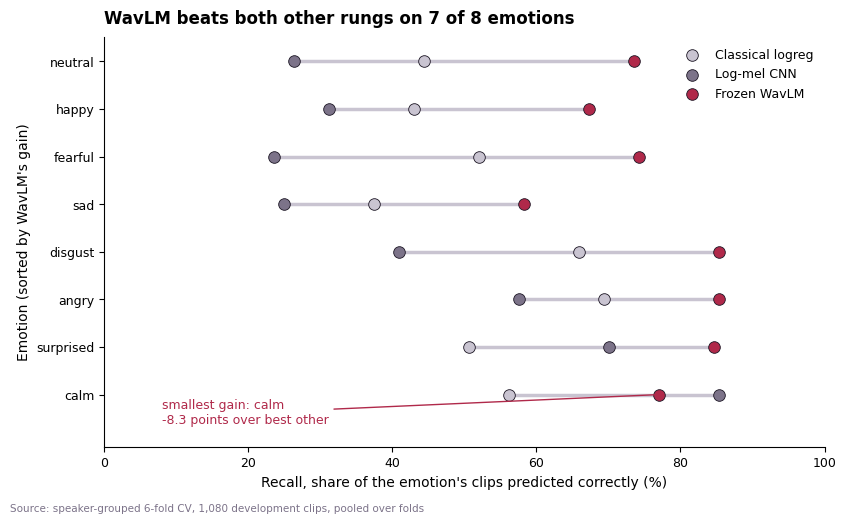

In [5]:
# F10b: recall of each emotion on the three rungs, sorted by the gain.
order = rr.sort_values("wavlm - best other").index
fig, ax = plt.subplots(figsize=(8.5, 5.2))
for y, e in enumerate(order):
    lo, hi = rr.loc[e, RUNGS].min(), rr.loc[e, RUNGS].max()
    ax.plot([lo, hi], [y, y], color=U.MUTED, lw=2.5, zorder=1)
for m in RUNGS:
    ax.scatter(rr.loc[order, m], range(len(order)), s=70,
               color=RUNG_COLOR[m], edgecolor=U.INK, linewidth=0.6,
               zorder=3, label=RUNG_LABEL[m])
ax.set_yticks(range(len(order)), order)
ax.set_xlim(0, 100)
ax.set_ylim(-1.1, len(order) - 0.5)
worst = rr["wavlm - best other"].idxmin()
ax.annotate(
    f"smallest gain: {worst}\n"
    f"{rr.loc[worst, 'wavlm - best other']:+.1f} points over best other",
    xy=(rr.loc[worst, "wavlm"], list(order).index(worst)),
    xytext=(8, list(order).index(worst) - 0.62),
    fontsize=9, color=U.ACCENT,
    arrowprops={"arrowstyle": "-", "color": U.ACCENT})
U.finish_axes(
    ax,
    f"WavLM beats both other rungs on {lifts} of 8 emotions",
    "Recall, share of the emotion's clips predicted correctly (%)",
    "Emotion (sorted by WavLM's gain)",
    source=("Source: speaker-grouped 6-fold CV, 1,080 development "
            "clips, pooled over folds"),
    legend=True)
U.save_figure(fig, "F10b_recall_by_rung.png", out_dir=FIGS)
plt.show()

**Verdict: partly supported. [EVIDENCE]** WavLM beats both other rungs on 7 of 8 emotions, by 14.6 to 29.2 points of recall. The exception is calm, where the CNN reaches 85.4% against WavLM's 77.1%. Sad stays the weakest emotion for logistic regression (37.5%) and for WavLM (58.3%).

**So we** expect the encoder to help most emotions, name calm as the case where the CNN leads, and treat sad as the emotion the ladder has not solved.

### H32 · The same emotion pairs stay confused at every rung

**Why it matters:** if a better model only shifted its mistakes to new
pairs, one fix (more data, a different feature) could not target them;
if the pairs persist, they are a property of the audio dataset and the
limitation belongs on the slide.

In [6]:
# Confusion counts (true x predicted) pooled over the six folds, and
# the unordered pairs ranked by how many errors they account for.
CM = {m: pd.crosstab(PRED[m]["true_emotion"], PRED[m]["pred_emotion"])
      .reindex(index=EMOS, columns=EMOS, fill_value=0)
      for m in ALL_MODELS}


def pair_errors(cm: pd.DataFrame) -> pd.Series:
    """Errors per unordered emotion pair, largest first."""
    pairs = {}
    for i, a in enumerate(EMOS):
        for b in EMOS[i + 1:]:
            pairs[f"{a} <-> {b}"] = int(cm.loc[a, b] + cm.loc[b, a])
    return pd.Series(pairs).sort_values(ascending=False, kind="stable")


rows, top = [], {}
for m in ALL_MODELS:
    cm = CM[m]
    n_err = int(cm.values.sum() - np.trace(cm.values))
    pe = pair_errors(cm)
    for name, n in pe.items():
        rows.append({"model": m, "pair": name, "errors": n,
                     "share_of_errors_pct": 100 * n / n_err})
    if m in RUNGS:
        top[m] = list(pe.index[:5])
        print(f"{m:<7} errors {n_err:>4} of {int(cm.values.sum())} "
              f"({100 * n_err / cm.values.sum():.1f}%)")
        for name in pe.index[:5]:
            print(f"    {name:<24}{pe[name]:>4} "
                  f"({100 * pe[name] / n_err:.1f}% of its errors)")
pairs = pd.DataFrame(rows)
pairs.round(2).to_csv(TABLES / "confusion_pairs_by_rung.csv", index=False)

w_top3 = top["wavlm"][:3]
in_lr = [p in top["logreg"] for p in w_top3]
in_cnn = [p in top["cnn"] for p in w_top3]
print(f"wavlm top-3 pairs: {w_top3}")
print(f"  also in logreg top-5: {sum(in_lr)} of 3;"
      f" also in cnn top-5: {sum(in_cnn)} of 3")
worst_hit = min(sum(in_lr), sum(in_cnn))
verdict = ("supported" if worst_hit == 3 else
           "partly supported" if worst_hit == 2 else "not supported")
record(
    "H32",
    "The same emotion pairs stay confused at every rung",
    verdict,
    f"wavlm top-3 pairs {w_top3}; in logreg top-5: {sum(in_lr)}/3, "
    f"in cnn top-5: {sum(in_cnn)}/3",
    {"supported": "treat the persistent pairs as a limit of the audio "
                  "dataset",
     "partly supported": "report the pairs that persist and those that "
                         "move",
     "not supported": "report calm and sad as the persistent pair; the "
                      "other pairs move with the model",
     }[verdict],
)

logreg  errors  508 of 1080 (47.0%)
    calm <-> sad              47 (9.3% of its errors)
    happy <-> fearful         41 (8.1% of its errors)
    sad <-> disgust           36 (7.1% of its errors)
    neutral <-> sad           34 (6.7% of its errors)
    surprised <-> fearful     33 (6.5% of its errors)
cnn     errors  580 of 1080 (53.7%)
    calm <-> sad              59 (10.2% of its errors)
    neutral <-> calm          56 (9.7% of its errors)
    happy <-> fearful         43 (7.4% of its errors)
    sad <-> happy             40 (6.9% of its errors)
    happy <-> angry           39 (6.7% of its errors)
wavlm   errors  260 of 1080 (24.1%)
    sad <-> fearful           36 (13.8% of its errors)
    calm <-> sad              29 (11.2% of its errors)
    neutral <-> calm          22 (8.5% of its errors)
    neutral <-> sad           20 (7.7% of its errors)
    happy <-> surprised       19 (7.3% of its errors)
wavlm top-3 pairs: ['sad <-> fearful', 'calm <-> sad', 'neutral <-> calm']
  al

saved Evaluation/outputs/figures/F10_confusion_by_rung.png


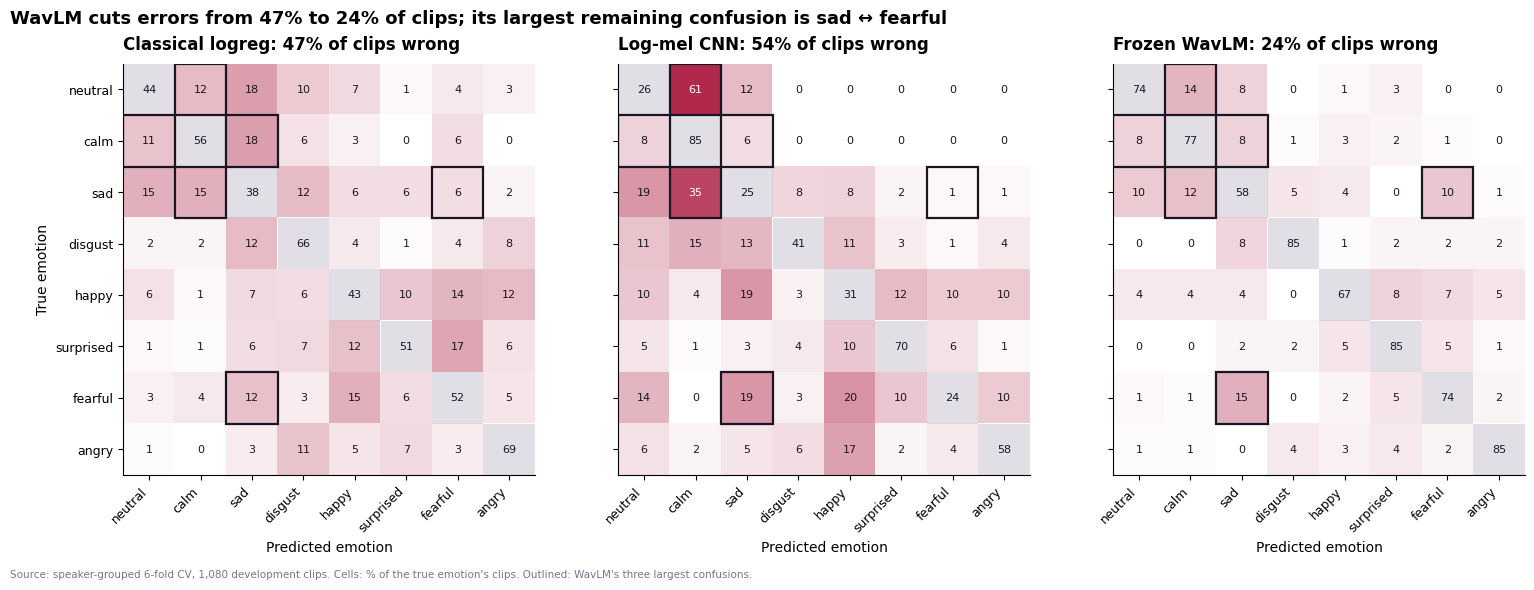

In [7]:
# F10: row-normalised confusion matrices of the three rungs. Errors
# (off-diagonal) carry the colour; correct answers are muted.
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle

err_cmap = LinearSegmentedColormap.from_list(
    "err", ["#FFFFFF", U.ACCENT])
n_err = {m: int(CM[m].values.sum() - np.trace(CM[m].values))
         for m in RUNGS}
err_pct = {m: 100 * n_err[m] / CM[m].values.sum() for m in RUNGS}
top_pair = w_top3[0].split(" <-> ")

fig, axes = plt.subplots(1, 3, figsize=(16, 5.6), sharey=True)
for ax, m in zip(axes, RUNGS):
    frac = CM[m].div(CM[m].sum(axis=1), axis=0).values * 100
    shown = np.where(np.eye(8, dtype=bool), np.nan, frac)
    ax.imshow(shown, cmap=err_cmap, vmin=0, vmax=40)
    for i in range(8):
        ax.add_patch(Rectangle((i - .5, i - .5), 1, 1,
                               color=U.MUTED, alpha=.55, lw=0))
        for j in range(8):
            ax.text(j, i, f"{frac[i, j]:.0f}", ha="center",
                    va="center", fontsize=8,
                    color=U.INK if i == j or frac[i, j] < 25 else "w")
    for pair in w_top3:
        a, b = pair.split(" <-> ")
        for r_, c_ in ((a, b), (b, a)):
            ax.add_patch(Rectangle(
                (EMOS.index(c_) - .5, EMOS.index(r_) - .5), 1, 1,
                fill=False, edgecolor=U.INK, lw=1.6))
    ax.set_xticks(range(8), EMOS, rotation=45, ha="right")
    ax.set_yticks(range(8), EMOS)
    U.finish_axes(
        ax,
        f"{RUNG_LABEL[m]}: {err_pct[m]:.0f}% of clips wrong",
        "Predicted emotion", "True emotion" if m == "logreg" else "",
        source=("Source: speaker-grouped 6-fold CV, 1,080 development "
                "clips. Cells: % of the true emotion's clips. Outlined: "
                "WavLM's three largest confusions.")
        if m == "wavlm" else "")
fig.suptitle(
    f"WavLM cuts errors from {err_pct['logreg']:.0f}% to "
    f"{err_pct['wavlm']:.0f}% of clips; its largest remaining confusion "
    f"is {top_pair[0]} ↔ {top_pair[1]}",
    x=0.01, y=1.02, ha="left", fontsize=13, fontweight="600")
U.save_figure(fig, "F10_confusion_by_rung.png", out_dir=FIGS)
plt.show()

**Verdict: not supported. [EVIDENCE]** Only one of WavLM's three largest confusions is also in the classical top five (1 of 3), and two of three are in the CNN's (2 of 3). Calm and sad is the pair that survives: it is the largest confusion for logistic regression and the CNN and the second largest for WavLM. The classical rung's happy and fearful and surprised and fearful pairs drop out of WavLM's top five, while sad and fearful, new to it, becomes its largest.

**So we** report calm and sad as the confusion that survives every rung, and describe the other pairs as moving with the model.

### H33 · The gain over logistic regression reaches every development speaker

**Why it matters:** a mean can hide a model that only works for a few
voices. A deployed tool meets new speakers, so a gain that some speakers
do not share would be a gain we cannot promise.

In [8]:
# Macro-F1 of each speaker's 60 clips (each dev speaker sits in exactly
# one held-out fold, so every score comes from a model that never saw
# that voice).
def speaker_macro_f1(df: pd.DataFrame) -> pd.Series:
    """Macro-F1 per speaker (unitless, 0-1)."""
    return pd.Series({
        s: f1_score(g["true_emotion"], g["pred_emotion"],
                    average="macro", labels=EMOS, zero_division=0)
        for s, g in df.groupby("speaker")})


spk = pd.DataFrame({m: speaker_macro_f1(PRED[m]) for m in ALL_MODELS})
spk.index.name = "speaker"
spk.round(4).to_csv(TABLES / "per_speaker_macro_f1.csv")
view = spk[RUNGS].copy()
view["wavlm - logreg"] = view["wavlm"] - view["logreg"]
display(view.round(3))
n_spk = len(view)
wins = int((view["wavlm - logreg"] > 0).sum())
wins_cnn = int((view["wavlm"] > view["cnn"]).sum())
sign_p = stats.binomtest(wins, n_spk, 0.5).pvalue
print(f"speakers where wavlm > logreg: {wins} of {n_spk} "
      f"(sign test p = {sign_p:.2e})")
print(f"speakers where wavlm > cnn:    {wins_cnn} of {n_spk}")
for m in RUNGS:
    print(f"{m:<7} speaker mean {spk[m].mean():.3f}, "
          f"sd {spk[m].std(ddof=1):.3f}, "
          f"worst speaker {spk[m].idxmin()} ({spk[m].min():.3f})")
verdict = ("supported" if wins == n_spk else
           "partly supported" if wins >= 0.8 * n_spk else
           "not supported")
record(
    "H33",
    "The gain over logistic regression reaches every development "
    "speaker",
    verdict,
    f"wavlm > logreg for {wins} of {n_spk} speakers (sign test "
    f"p = {sign_p:.1e}); worst wavlm speaker "
    f"{spk['wavlm'].idxmin()} {spk['wavlm'].min():.3f}",
    {"supported": "quote the gain as holding for every speaker",
     "partly supported": "quote the gain per speaker and name the "
                         "speaker it misses",
     "not supported": "do not quote the gain as general across voices",
     }[verdict],
)

,logreg,cnn,wavlm,wavlm - logreg
speaker,,,,
2,0.665,0.456,0.872,0.207
3,0.687,0.513,0.826,0.140
5,0.451,0.349,0.826,0.375
6,0.548,0.309,0.858,0.310
7,0.557,0.452,0.770,0.212
10,0.485,0.296,0.783,0.297
11,0.453,0.378,0.692,0.240
12,0.541,0.436,0.792,0.252
13,0.439,0.294,0.387,-0.052


speakers where wavlm > logreg: 17 of 18 (sign test p = 1.45e-04)
speakers where wavlm > cnn:    18 of 18
logreg  speaker mean 0.492, sd 0.090, worst speaker 15 (0.343)
cnn     speaker mean 0.415, sd 0.096, worst speaker 13 (0.294)
wavlm   speaker mean 0.742, sd 0.113, worst speaker 13 (0.387)

H33 · The gain over logistic regression reaches every development speaker
    verdict: PARTLY SUPPORTED


saved Evaluation/outputs/figures/F10c_gain_per_speaker.png


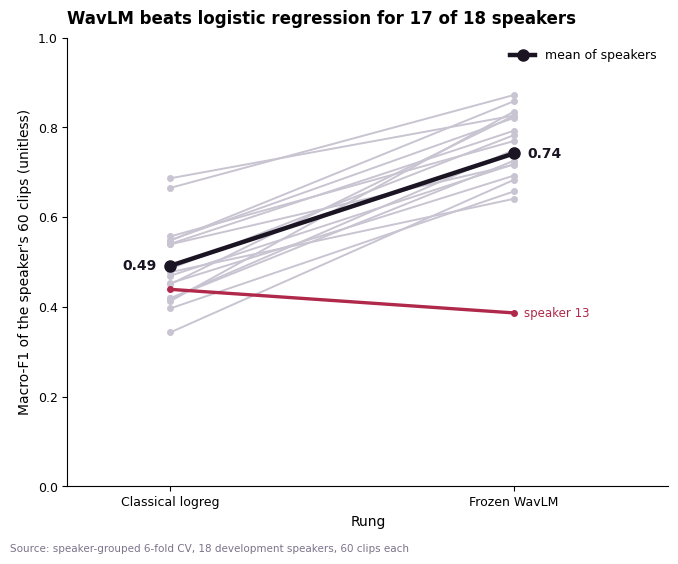

In [9]:
# F10c: one line per speaker from logreg to WavLM. Speakers that do not
# improve are drawn in the accent colour; the rest are context.
fig, ax = plt.subplots(figsize=(6.8, 5.6))
for s in view.index:
    up = view.loc[s, "wavlm - logreg"] > 0
    ax.plot([0, 1], [view.loc[s, "logreg"], view.loc[s, "wavlm"]],
            color=U.MUTED if up else U.ACCENT, lw=1.4 if up else 2.4,
            marker="o", ms=4, zorder=2 if up else 4)
    if not up:
        ax.text(1.03, view.loc[s, "wavlm"], f"speaker {s}",
                fontsize=8.5, color=U.ACCENT, va="center")
means = view[["logreg", "wavlm"]].mean()
ax.plot([0, 1], means.values, color=U.INK, lw=3.2, marker="o", ms=8,
        zorder=5, label="mean of speakers")
for x, val in zip((0, 1), means.values):
    ax.text(x + (-0.04 if x == 0 else 0.04), val, f"{val:.2f}",
            ha="right" if x == 0 else "left", va="center",
            fontsize=10, fontweight="600", color=U.INK)
ax.set_xticks([0, 1], ["Classical logreg", "Frozen WavLM"])
ax.set_xlim(-0.3, 1.45)
ax.set_ylim(0, 1)
U.finish_axes(
    ax,
    f"WavLM beats logistic regression for {wins} of {n_spk} speakers",
    "Rung", "Macro-F1 of the speaker's 60 clips (unitless)",
    source=("Source: speaker-grouped 6-fold CV, 18 development "
            "speakers, 60 clips each"),
    legend=True)
U.save_figure(fig, "F10c_gain_per_speaker.png", out_dir=FIGS)
plt.show()

**Verdict: partly supported. [EVIDENCE]** WavLM beats logistic regression for 17 of 18 speakers (sign test p = 1.45e-04) and the CNN for 18 of 18. The exception is speaker 13, who scores 0.387 with WavLM against 0.439 with logistic regression and is WavLM's weakest voice. The spread across speakers is wider for WavLM (sd 0.113) than for logistic regression (sd 0.090).

**So we** quote the gain as 17 of 18 speakers and name speaker 13 as the case to watch, since a new voice can still fall below the classical rung.

### H34 · A prediction's confidence separates right answers from wrong ones at every rung

**Why it matters:** any triage rule ("act only when the model is
sure") relies on this. If confidence carried no information at some
rung, thresholds tuned on it would be arbitrary.

In [10]:
# AUROC = chance that a randomly chosen correct prediction has higher
# confidence than a randomly chosen wrong one (0.5 = no information).
# Bins hold equal numbers of clips, ordered by confidence.
rows, bins = [], {}
for m in ALL_MODELS:
    df = PRED[m]
    auc = roc_auc_score(df["correct"], df["pred_confidence"])
    q = pd.qcut(df["pred_confidence"].rank(method="first"), 5,
                labels=False)
    g = df.groupby(q).agg(conf=("pred_confidence", "mean"),
                          acc=("correct", "mean"))
    bins[m] = g
    rows.append({
        "model": m, "auroc": auc,
        "mean_confidence": df["pred_confidence"].mean(),
        "accuracy": df["correct"].mean(),
        "accuracy_least_confident_fifth": g["acc"].iloc[0],
        "accuracy_most_confident_fifth": g["acc"].iloc[-1],
    })
conf = pd.DataFrame(rows)
conf.round(4).to_csv(TABLES / "confidence_by_rung.csv", index=False)
display(conf[conf["model"].isin(RUNGS)].round(3))
auc = conf.set_index("model")["auroc"]
floor = 0.65
print(f"bar for supported: AUROC of at least {floor} at every rung")
verdict = ("supported" if (auc[RUNGS] >= floor).all() else
           "partly supported" if (auc[RUNGS] >= floor).any() else
           "not supported")
record(
    "H34",
    "A prediction's confidence separates right answers from wrong "
    "ones at every rung",
    verdict,
    "AUROC " + ", ".join(f"{m} {auc[m]:.3f}" for m in RUNGS)
    + f" (bar {floor})",
    {"supported": "build the flag rule in `07` on confidence, "
                  "comparing rungs at equal flag rate",
     "partly supported": "build the flag rule only on the rungs where "
                         "confidence separates",
     "not supported": "do not build a flag rule on confidence",
     }[verdict],
)

,model,auroc,mean_confidence,accuracy,accuracy_least_confident_fifth,accuracy_most_confident_fifth
0,logreg,0.716,0.644,0.530,0.287,0.824
4,cnn,0.721,0.380,0.463,0.241,0.796
7,wavlm,0.767,0.808,0.759,0.463,0.949


bar for supported: AUROC of at least 0.65 at every rung

H34 · A prediction's confidence separates right answers from wrong ones at every rung
    verdict: SUPPORTED


saved Evaluation/outputs/figures/F10d_confidence_vs_accuracy.png


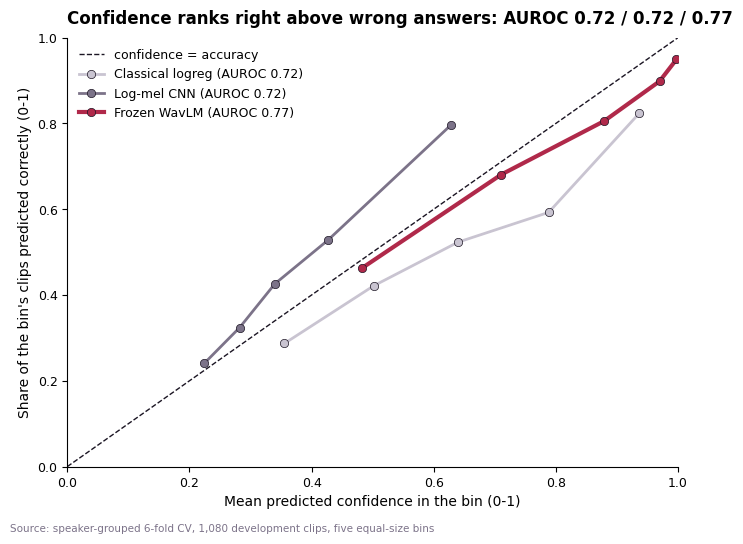

In [11]:
# F10d: accuracy in five equal-size confidence bins, per rung.
fig, ax = plt.subplots(figsize=(7, 5.4))
ax.plot([0, 1], [0, 1], ls="--", color=U.INK, lw=1,
        label="confidence = accuracy")
for m in RUNGS:
    g = bins[m]
    ax.plot(g["conf"], g["acc"], marker="o",
            color=RUNG_COLOR[m], lw=3 if m == "wavlm" else 2,
            markeredgecolor=U.INK, markeredgewidth=0.5,
            label=f"{RUNG_LABEL[m]} (AUROC {auc[m]:.2f})")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
U.finish_axes(
    ax,
    f"Confidence ranks right above wrong answers: AUROC "
    f"{auc['logreg']:.2f} / {auc['cnn']:.2f} / {auc['wavlm']:.2f}",
    "Mean predicted confidence in the bin (0-1)",
    "Share of the bin's clips predicted correctly (0-1)",
    source=("Source: speaker-grouped 6-fold CV, 1,080 development "
            "clips, five equal-size bins"),
    legend=True)
U.save_figure(fig, "F10d_confidence_vs_accuracy.png", out_dir=FIGS)
plt.show()

**Verdict: supported. [EVIDENCE]** AUROC is 0.716 for logistic regression, 0.721 for the CNN and 0.767 for WavLM, all above the bar of 0.65. In the most confident fifth of clips accuracy is 0.824, 0.796 and 0.949, against 0.287, 0.241 and 0.463 in the least confident fifth. Calibration differs by rung: mean confidence against accuracy is 0.644 against 0.530 for logistic regression (over-confident), 0.380 against 0.463 for the CNN (under-confident) and 0.808 against 0.759 for WavLM.

**So we** build the flag rule in `07` on confidence, but compare the rungs at equal flag rate, because one threshold selects a different share of clips at each rung.

---
## Summary

In [12]:
summary = pd.DataFrame(SUMMARY).set_index("H")
with pd.option_context("display.max_colwidth", 88):
    display(summary)
summary.to_csv(TABLES / "summary_06.csv")

,hypothesis,verdict,evidence,so we
H,,,,
H31,The pretrained encoder lifts recall for every emotion above both other rungs,partly supported,wavlm beats logreg and cnn on 7 of 8 emotions; weakest emotion sad 37.5% (logreg) ->...,"expect the encoder to help most emotions, and name the exceptions"
H32,The same emotion pairs stay confused at every rung,not supported,"wavlm top-3 pairs ['sad <-> fearful', 'calm <-> sad', 'neutral <-> calm']; in logreg...",report calm and sad as the persistent pair; the other pairs move with the model
H33,The gain over logistic regression reaches every development speaker,partly supported,wavlm > logreg for 17 of 18 speakers (sign test p = 1.4e-04); worst wavlm speaker 13...,quote the gain per speaker and name the speaker it misses
H34,A prediction's confidence separates right answers from wrong ones at every rung,supported,"AUROC logreg 0.716, cnn 0.721, wavlm 0.767 (bar 0.65)","build the flag rule in `07` on confidence, comparing rungs at equal flag rate"


**Hands on:** the per-rung confidence used by `07_Flag_rate_and_threshold`
is `pred_confidence` from the same fold files; `outputs/tables/` holds
the recall, pair, speaker and confidence tables for the report.